가중치+편향 개수: 51450
epoch 1: 정확도 0.894
epoch 2: 정확도 0.927
epoch 3: 정확도 0.942
epoch 4: 정확도 0.951
epoch 5: 정확도 0.958


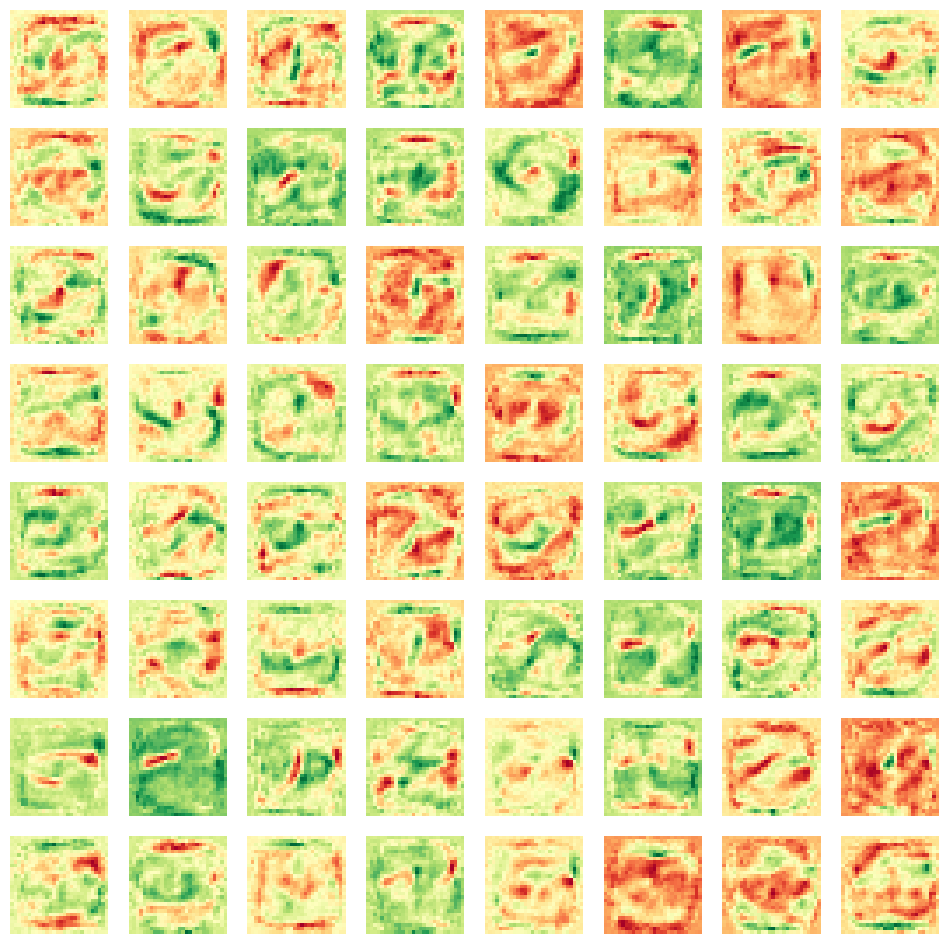

In [ ]:
import numpy as np
import torch, torch.nn as nn
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

tf = transforms.ToTensor()  # 이미지를 0~1 사이 숫자의 픽셀 밝기로 바꿈
train = datasets.MNIST('.', train=True, download=True, transform=tf)  # 학습용 손글씨 숫자 이미지 (28x28)
test = datasets.MNIST('.', train=False, download=True, transform=tf)  # 시험용
train_loader = torch.utils.data.DataLoader(train, batch_size=64, shuffle=True) # 이미지를 64장씩 묶음으로 꺼냄
test_loader = torch.utils.data.DataLoader(test, batch_size=1000)

model = nn.Sequential(
    nn.Flatten(),                         # 28x28 이미지를 한줄로 펼침 - 입력층 뉴런 784개
    nn.Linear(784,64), nn.Sigmoid(),      # W(64x784) * a + b 계산 - 행렬곱 + 편향 (W와 b 자동 생성)
    nn.Linear(64,16), nn.Sigmoid(),
    nn.Linear(16,10)
)

print("가중치+편향 개수:", sum(p.numel() for p in model.parameters()))


loss_fn = nn.CrossEntropyLoss()  # 손실 함수(얼마나 틀렸나 점수)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)  # 학습률


# 학습 반복문
for epoch in range(5):                  # 5번 반복
    for x, y in train_loader:           # x = 이미지,  y = 정답(숫자)
        opt.zero_grad()                 # 이전 계산 흔적 지우기
        loss_fn(model(x),y).backward()  # 현재 가중치로 답 내보고 얼마나 틀렸나 계산
        opt.step()                      # 계산된 방향대로 가중치와 편향 수정

    correct = sum((model(x).argmax(1) == y).sum().item() for x, y in test_loader)  # 가장 높은 숫자를 답으로 고르고 비교 후 맞은 개수 세기
    print(f"epoch {epoch+1}: 정확도 {correct/len(test):.3f}")


# 그림으로
Wt = model[1].weight.detach()                       # model[0] = Flatten, model[1] = 첫번째 Linear층의 가중치
fig, axes = plt.subplots(8,8,figsize=(12,12))       # fig:도화지 전체 (12x12), axes = 8x8격자 칸들
for i, ax in enumerate(axes.flat):                  # flat: 격자를 한줄로 펼침, enumerate: 번호 붙이기 (i: 뉴런번호, ax: 칸)
    ax.imshow(Wt[i].reshape(28,28), cmap="RdYlGn")  # Wt[i]: i번째 뉴런의 가중치 784개 -> 28x28로 접고 색칠하기 (Rd: 음수, Yl: 0근처, Gn: 양수)
    ax.axis("off")                                  # 눈금, 테두리 제거
plt.show()



정답: 4  모델의 답: 4


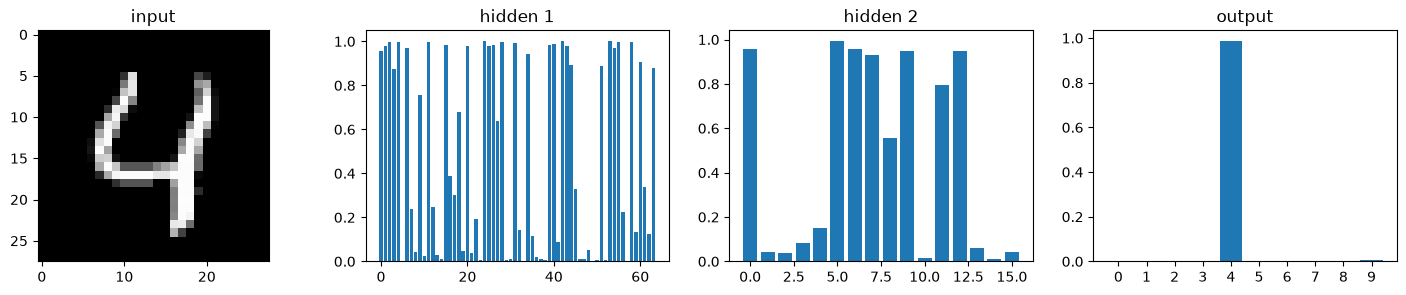

In [ ]:
# 판별 과정
idx = 4                             # 테스트 이미지 번호
x, y = test[idx]                     # x: 이미지, y: 정답

with torch.no_grad():
    a0 = x.view(-1)                  # 입력층: 픽셀 784개
    z1 = model[1](a0)                # W·a + b (첫 번째 은닉층, 시그모이드 전)
    a1 = model[2](z1)                # 시그모이드 적용 → 0~1
    z2 = model[3](a1)                # 두 번째 은닉층, 시그모이드 전
    a2 = model[4](z2)                # 시그모이드 적용
    z3 = model[5](a2)                # 출력층 점수 10개
    probs = torch.softmax(z3, dim=0) # 점수를 확률로 변환

print("정답:", y, " 모델의 답:", probs.argmax().item())

fig, axes = plt.subplots(1, 4, figsize=(18, 3))
axes[0].imshow(x.squeeze(), cmap="gray"); axes[0].set_title("input")     # 이미지
axes[1].bar(range(len(a1)), a1);          axes[1].set_title("hidden 1")  # 첫 은닉층 뉴런들의 값
axes[2].bar(range(len(a2)), a2);          axes[2].set_title("hidden 2")  # 앞의 패턴을 조합
axes[3].bar(range(10), probs);            axes[3].set_title("output")    # 가장 높은 막대
axes[3].set_xticks(range(10))
plt.show()